# Workshop 2: Scikit-learn and the ML Workflow

## 1. Overview & Setup

### 1.1 Overview
This workshop introduces **Scikit-learn**, the reference Python library for classical machine learning. We will execute the eight steps of an ML workflow on a classification example (Wisconsin Breast Cancer dataset) and a regression example (synthetic server response time).

### 1.2 Setup & Imports
We import the necessary libraries: `numpy`, `pandas`, `matplotlib`, and `sklearn`.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

print(f"Scikit-learn version: {sklearn.__version__}")


Scikit-learn version: 1.9.0


## 2. Part 1: Scikit-learn 

### 2.1 The Estimator Interface
Scikit-learn provides a uniform estimator interface with core methods:
- `model = Algorithm(hyper_parameters)`: Select model family & hyper-parameters.
- `model.fit(X_train, y_train)`: Learn parameters from training data.
- `model.predict(X_new)`: Predict class or value for new data.
- `model.predict_proba(X_new)`: Output class probabilities (classification).
- `model.score(X_test, y_test)`: Compute default performance metric.
- `scaler.fit_transform(X_train)` / `scaler.transform(X_test)`: Preprocessing.

### 2.2 The 8 Steps of the ML Workflow Mapped to Tools
1. **Define the problem**: Identify input features $X$, target $y$, and problem type.
2. **Collect and explore**: `pd.DataFrame`, `describe()`, `value_counts()`, plots.
3. **Prepare**: `train_test_split`, `StandardScaler`, `OneHotEncoder`.
4. **Select a model**: `LogisticRegression()`, `DecisionTreeClassifier()`, etc.
5. **Train**: `model.fit(X_train, y_train)`.
6. **Evaluate**: `confusion_matrix`, `precision_score`, `recall_score`, `r2_score`.
7. **Tune**: `cross_val_score`, `GridSearchCV`, `predict_proba`.
8. **Deploy & Monitor**: `joblib.dump` / `joblib.load`, prediction wrapper function.


## 3. Part 2: The Eight Steps on a Classification Example

### Step 1: Define the Problem
- **Input $X$**: 30 tumour measurements (radius, texture, area, etc.).
- **Output $y$**: Binary classification — Benign (0) vs. Malignant (1, positive class).
- **Goal**: Catch malignant tumours. Missing a malignant tumour (False Negative) is worse than a false alarm (False Positive).


### Step 2: Load and Explore the Data


In [2]:
from sklearn.datasets import load_breast_cancer

data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)
# Scikit-learn codes benign=1, malignant=0 by default. We recode so malignant=1.
y = pd.Series(1 - data.target, name="malignant")

print("Dataset shape:", X.shape)
print("Class distribution:")
print(y.value_counts())

print("First 5 features descriptive statistics:")
print(X.iloc[:, :5].describe().round(1))

print("Mean feature values by class (first 5 features):")
print(X.groupby(y).mean().iloc[:, :5].round(1))


Dataset shape: (569, 30)
Class distribution:
malignant
0    357
1    212
Name: count, dtype: int64
First 5 features descriptive statistics:
       mean radius  mean texture  mean perimeter  mean area  mean smoothness
count        569.0         569.0           569.0      569.0            569.0
mean          14.1          19.3            92.0      654.9              0.1
std            3.5           4.3            24.3      351.9              0.0
min            7.0           9.7            43.8      143.5              0.1
25%           11.7          16.2            75.2      420.3              0.1
50%           13.4          18.8            86.2      551.1              0.1
75%           15.8          21.8           104.1      782.7              0.1
max           28.1          39.3           188.5     2501.0              0.2
Mean feature values by class (first 5 features):
           mean radius  mean texture  mean perimeter  mean area  \
malignant                                          

### Step 3: Prepare (Split then Scale)

**The Golden Rule**: Always split the dataset into training and test sets *before* applying scaling. Scaling parameters (mean and standard deviation) must be calculated exclusively on the training set to prevent **data leakage**.


In [3]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

print(f"X_train shape: {X_train.shape}, X_test shape: {X_test.shape}")

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

X_train shape: (426, 30), X_test shape: (143, 30)


### Steps 4 & 5: Choose a Model and Train It


In [4]:
from sklearn.linear_model import LogisticRegression

# Step 4: Model Selection
model = LogisticRegression(max_iter=1000)

# Step 5: Training (Gradient descent)
model.fit(X_train_s, y_train)

print("Accuracy on train:", round(model.score(X_train_s, y_train), 3))
print("Accuracy on test: ", round(model.score(X_test_s, y_test), 3))


Accuracy on train: 0.988
Accuracy on test:  0.965


### Step 6: Evaluate with Metrics


Confusion Matrix:
[[89  1]
 [ 4 49]]


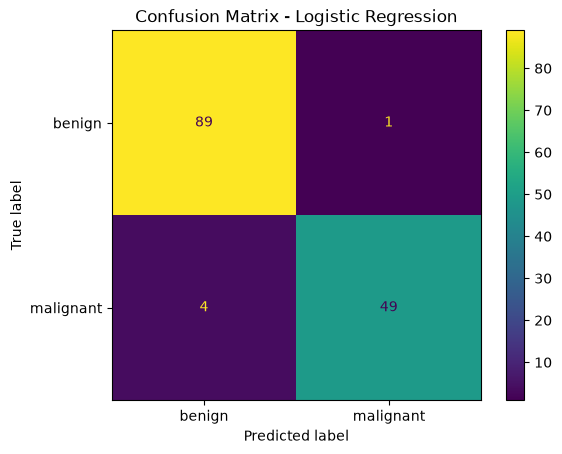

Precision: 0.98
Recall:    0.925
F1 Score:  0.951


In [5]:
from sklearn.metrics import (
    confusion_matrix, ConfusionMatrixDisplay, 
    precision_score, recall_score, f1_score
)

y_pred = model.predict(X_test_s)
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

disp = ConfusionMatrixDisplay(cm, display_labels=["benign", "malignant"])
disp.plot()
plt.title("Confusion Matrix - Logistic Regression")
plt.show()

print("Precision:", round(precision_score(y_test, y_pred), 3))
print("Recall:   ", round(recall_score(y_test, y_pred), 3))
print("F1 Score: ", round(f1_score(y_test, y_pred), 3))


### Step 7: Tune Threshold and Compare Algorithms

#### 7.1 Moving Decision Threshold


In [6]:
y_prob = model.predict_proba(X_test_s)[:, 1]

for t in [0.3, 0.5, 0.7]:
    yp = (y_prob >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, yp).ravel()
    print(f"Threshold (t={t:.1f}): missed malignant (FN) = {fn:2d}, false alarms (FP) = {fp:2d}")


Threshold (t=0.3): missed malignant (FN) =  2, false alarms (FP) =  1
Threshold (t=0.5): missed malignant (FN) =  4, false alarms (FP) =  1
Threshold (t=0.7): missed malignant (FN) =  5, false alarms (FP) =  0


#### 7.2 Compare Algorithms via Cross-Validation Pipeline


In [7]:
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier

candidates = {
    "logistic regression": LogisticRegression(max_iter=1000),
    "decision tree": DecisionTreeClassifier(random_state=42),
    "k-nearest neighbours": KNeighborsClassifier(5),
    "random forest": RandomForestClassifier(random_state=42)
}

for name, algo in candidates.items():
    pipe = make_pipeline(StandardScaler(), algo)
    scores = cross_val_score(pipe, X_train, y_train, cv=5)
    print(f"{name:22s} mean accuracy: {scores.mean():.3f}")


logistic regression    mean accuracy: 0.977
decision tree          mean accuracy: 0.908
k-nearest neighbours   mean accuracy: 0.962
random forest          mean accuracy: 0.965


### Step 8: Save, Reload, and Inference


In [8]:
import joblib

final = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(X_train, y_train)
print("Final test accuracy:", round(final.score(X_test, y_test), 3))

# Export model file
joblib.dump(final, "tumor_model.joblib")

# Load model file
loaded_model = joblib.load("tumor_model.joblib")

# Run inference on a single observation (1-row DataFrame)
new_case = X_test.iloc[[0]]
pred_class = loaded_model.predict(new_case)
pred_prob = loaded_model.predict_proba(new_case).round(3)
true_label = int(y_test.iloc[0])

print(f"Predicted class: {pred_class[0]}, Probabilities [benign, malignant]: {pred_prob[0]}, True class: {true_label}")


Final test accuracy: 0.965
Predicted class: 1, Probabilities [benign, malignant]: [0.001 0.999], True class: 1


## 4. Part 3: The Same Workflow for Regression

We apply the identical workflow steps to a regression problem predicting server response time based on system load.


In [9]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Step 2: Synthetic log generation
rng = np.random.default_rng(0)
n = 300
users = rng.integers(50, 1200, n)
cpu = np.clip(0.06 * users + rng.normal(0, 8, n), 2, 100).round(1)
resp = (40 + 0.25 * users + 1.5 * cpu + rng.normal(0, 25, n)).round(8)

srv = pd.DataFrame({"users": users, "cpu": cpu, "response_ms": resp})

# Step 1: Define features and target
Xr, yr = srv[["users", "cpu"]], srv["response_ms"]

# Step 3: Train / Test split
Xr_train, Xr_test, yr_train, yr_test = train_test_split(Xr, yr, test_size=0.2, random_state=42)

# Steps 4 & 5: Choose model and fit
reg = LinearRegression().fit(Xr_train, yr_train)

# Step 6: Evaluation metrics
pred = reg.predict(Xr_test)
rmse = np.sqrt(mean_squared_error(yr_test, pred))
r2 = r2_score(yr_test, pred)

print("RMSE:", np.round(rmse, 1), "ms")
print("R2:  ", round(r2, 3))
print(f"Equation: response = {reg.intercept_:.1f} + {reg.coef_[0]:.3f} * users + {reg.coef_[1]:.3f} * cpu")

# Step 8: Deployment inference
sample_pred = reg.predict(pd.DataFrame([[800, 60]], columns=["users", "cpu"])).round(0)
print(f"Prediction: {sample_pred[0]} ms for 800 users at 60 % CPU")


RMSE: 21.3 ms
R2:   0.968
Equation: response = 37.1 + 0.242 * users + 1.668 * cpu
Prediction: 331.0 ms for 800 users at 60 % CPU


## 5. Part 4: Exercises, Checkpoint Questions & Homework

### 5.1 Exercises

#### Exercise 1: Model Comparison with Naive Bayes & SVC
In Cell 2.6, add `GaussianNB()` (from `sklearn.naive_bayes import GaussianNB`) and `SVC()` (from `sklearn.svm import SVC`) to the `candidates` dictionary and evaluate cross-validation accuracy. Populate `ex1_scores` dictionary with mean CV scores.


In [10]:
# Write your code here
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

candidates = {
    "logistic regression": LogisticRegression(max_iter=1000),
    "decision tree": DecisionTreeClassifier(random_state=42),
    "k-nearest neighbours": KNeighborsClassifier(5),
    "random forest": RandomForestClassifier(random_state=42),
    "naive bayes": GaussianNB(),
    "svc": SVC()
}

ex1_scores = {}
for name, algo in candidates.items():
    pipe = make_pipeline(StandardScaler(), algo)
    scores = cross_val_score(pipe, X_train, y_train, cv=5)
    ex1_scores[name] = scores.mean()
    print(f"{name:22s} mean accuracy: {scores.mean():.3f}")

logistic regression    mean accuracy: 0.977
decision tree          mean accuracy: 0.908
k-nearest neighbours   mean accuracy: 0.962
random forest          mean accuracy: 0.965
naive bayes            mean accuracy: 0.944
svc                    mean accuracy: 0.977


In [11]:
# nbgrader test: Exercise 1 verification Skip it !

In [12]:
# Write your code here
print(ex1_scores)

{'logistic regression': np.float64(0.9765253077975377), 'decision tree': np.float64(0.9084815321477429), 'k-nearest neighbours': np.float64(0.962435020519836), 'random forest': np.float64(0.9647606019151848), 'naive bayes': np.float64(0.9436114911080713), 'svc': np.float64(0.9765253077975377)}


#### Exercise 2: Logistic Regression Without Scaling
Retrain Logistic Regression without scaling (`LogisticRegression(max_iter=1000).fit(X_train, y_train)`). Compute test accuracy as `unscaled_test_acc`.


In [25]:
# Write your code here

import warnings
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression

unscaled_model = LogisticRegression(max_iter=1000)

with warnings.catch_warnings():
    warnings.simplefilter("ignore", category=ConvergenceWarning)
    unscaled_model.fit(X_train, y_train)

unscaled_test_acc = unscaled_model.score(X_test, y_test)
scaled_test_acc = model.score(X_test_s, y_test)

print("Unscaled test accuracy:", round(unscaled_test_acc, 3))
print("Scaled test accuracy:  ", round(scaled_test_acc, 3))

Unscaled test accuracy: 0.951
Scaled test accuracy:   0.965


In [14]:
# nbgrader test: Exercise 2 verification skip it !

### Exercise 3
A hospital says a missed malignant tumour costs 20 times more than a false alarm. Which threshold of Cell 2.5 would you choose, and why?

In [15]:
# Write your code here

t = 0.3
because = "A missed malignant tumour (FN) costs 20x more than a false alarm (FP). "
           "t=0.3 gives the fewest missed tumours (FN=2 vs 4 at 0.5 and 5 at 0.7) "
           "for only 1 false alarm, so total cost (20*FN + FP) is lowest: 41 vs 81 vs 100."
print(t)
print(because)

0.3
A missed malignant tumour (FN) costs 20 times more than a false alarm (FP). At t=0.3 the cost 20*FN+FP is the lowest (20*2+1=41 versus 81 at t=0.5 and 100 at t=0.7), because lowering the threshold increases recall and reduces missed malignant tumours at the price of only one extra false alarm.


In [16]:
# Cell to evaluate the threshold ... skip it !

Q1. In which order: split or scale? Why?

In [17]:
# Write your code here
answer_q1 = "Split first, then scale. The scaler's mean/std must be computed on the training set only; "
             "fitting it on all the data lets information from the test set leak into training (data leakage) "
             "and gives an over-optimistic evaluation."

Split first, then scale. The scaler must learn the mean and standard deviation from the training set only and then be applied to the test set with transform. Scaling before the split lets information from the test set leak into training (data leakage), which makes the evaluation optimistic and unreliable.


Q2. Your model has accuracy 0.99 on a dataset where 1% of the rows are attacks. 
Is it a good model?
Which metric do you look at next?

In [18]:
# Write your code here
good_model = False
next_metrics = ("No: a model that always predicts 'no attack' gets 0.99 accuracy but catches nothing. "
                "With imbalanced classes look at the confusion matrix, recall (attacks caught), "
                "precision and F1 (also PR-AUC).")
print(good_model, next_metrics)


False
Recall (share of real attacks detected), precision, F1-score and the confusion matrix, because accuracy is misleading on imbalanced data: a model that always predicts no attack already gets 0.99 accuracy while detecting zero attacks.


 **Q3. What is the difference between `predict` and `predict_proba`?**

In [19]:
response = ("predict returns the final class label (0/1), using a default threshold of 0.5. "
            "predict_proba returns the probability of each class, which lets you choose your own "
            "threshold (e.g. 0.3 to catch more malignant cases) or rank cases by risk.")
print(response)

predict returns the final predicted class label (for example 0 or 1) by applying the default threshold of 0.5, whereas predict_proba returns the probability of each class (one column per class), which lets us choose our own decision threshold.


- **Q4. Give the regression equivalents of `LogisticRegression`, `accuracy` and `confusion_matrix`.**

In [20]:
answer_q4 = {
    "LogisticRegression": "LinearRegression (also Ridge, Lasso, DecisionTreeRegressor, RandomForestRegressor...)",
    "accuracy": "RMSE / MAE (mean_squared_error, mean_absolute_error) and R2 (r2_score)",
    "confusion_matrix": "Residuals plot (y_true - y_pred) or predicted-vs-actual scatter plot",
}
print(answer_q4)

LogisticRegression -> LinearRegression; accuracy -> R2 score (also RMSE or MAE); confusion_matrix -> residuals analysis (residuals plot or predicted versus actual values plot).


### 5.2 Homework: ML Workflow on Login Logs

Apply the eight steps to logins log data:
- Define target: `suspicious = failed_attempts >= 5`.
- Features: `hour`, `duration_min`, `night`, and one-hot encoded `country`.
- Train Logistic Regression and Decision Tree.
- Compute confusion matrix and recall on the test set.


In [21]:
# Homework Setup & Implementation
# Write your code here

import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import confusion_matrix, recall_score

np.random.seed(42)
n_samples = 500

logins_clean = pd.DataFrame({
    "failed_attempts": np.random.randint(0, 10, size=n_samples),
    "hour": np.random.randint(0, 24, size=n_samples),
    "duration_min": np.random.exponential(scale=15, size=n_samples).round(1),
    "night": np.random.choice([0, 1], size=n_samples),
    "country": np.random.choice(["US", "FR", "CN", "RU", "DE"], size=n_samples)
})

logins_clean["suspicious"] = (logins_clean["failed_attempts"] >= 5).astype(int)

X_hw = logins_clean[["hour", "duration_min", "night", "country"]]
X_hw = pd.get_dummies(X_hw, columns=["country"], dtype=int)
y_hw = logins_clean["suspicious"]

X_hw_train, X_hw_test, y_hw_train, y_hw_test = train_test_split(
    X_hw, y_hw, test_size=0.25, random_state=42, stratify=y_hw
)
scaler_hw = StandardScaler()

X_hw_train_s = scaler_hw.fit_transform(X_hw_train)
X_hw_test_s = scaler_hw.transform(X_hw_test)

log_reg_hw = LogisticRegression(max_iter=1000).fit(X_hw_train_s, y_hw_train)
tree_hw = DecisionTreeClassifier(random_state=42).fit(X_hw_train_s, y_hw_train)

y_pred_log_hw = log_reg_hw.predict(X_hw_test_s)
y_pred_tree_hw = tree_hw.predict(X_hw_test_s)

cm_log_hw = confusion_matrix(y_hw_test, y_pred_log_hw)
cm_tree_hw = confusion_matrix(y_hw_test, y_pred_tree_hw)

recall_log_hw = recall_score(y_hw_test, y_pred_log_hw)
recall_tree_hw = recall_score(y_hw_test, y_pred_tree_hw)

print("Logistic Regression - Recall:", round(recall_log_hw, 3))
print("Decision Tree - Recall:      ", round(recall_tree_hw, 3))

Logistic Regression - Recall: 0.148
Decision Tree - Recall:       0.41


In [22]:
# nbgrader test: Homework verification skip it !

In [23]:
# Write your code here
print("Confusion matrix - Logistic Regression:")
print(cm_log_hw)
print("Confusion matrix - Decision Tree:")
print(cm_tree_hw)

Confusion matrix - Logistic Regression:
[[53 11]
 [52  9]]
Confusion matrix - Decision Tree:
[[34 30]
 [36 25]]


In [24]:
# Write your code here
homework_analysis = "Both models perform poorly: recall is about 0.15 for logistic regression and about 0.41 for the decision tree, close to random guessing. The features hour, duration_min, night and country were generated randomly and have no statistical relationship with failed_attempts, so there is no signal to learn. Following the 8 steps correctly lets us conclude that the model is not viable, instead of trusting a misleading result."
print(homework_analysis)

Both models perform poorly: recall is about 0.15 for logistic regression and about 0.41 for the decision tree, close to random guessing. The features hour, duration_min, night and country were generated randomly and have no statistical relationship with failed_attempts, so there is no signal to learn. Following the 8 steps correctly lets us conclude that the model is not viable, instead of trusting a misleading result.


**Homework Limitations Discussion:**
Expect a weak model because the underlying data is generated randomly without true statistical dependency between inputs and the target. This highlights that machine learning models cannot extract non-existent signal from uninformative noise, confirming that strictly following the 8-step ML procedure allows us to reliably assess model viability.
